# WP12 — Gerçek S01 API denemesi: bağımsız salt okunur inceleme

Bu notebook yeni API isteği göndermez. Kullanıcının normal PowerShell'de çalıştırdığı kayıt üç HTTP aşaması içerir. Başarısız API üretimi, modelin Türkçe veya kaynak sadakati başarısızlığı olarak etiketlenmez. Önceki Gemma V1/V2 ve Qwen durumları değişmez.

,stage,method,path,HTTP_status,elapsed_seconds,request_id,HTTP_slot
0,model_access,GET,/models/gpt-5.4-mini,200,0.953,d21a1748-5e08-447b-b948-e8dca0f11bb9,1
1,input_token_count,POST,/responses/input_tokens,200,1.219,req_4ef5c250ec1e4622a8ae7b0727da037e,2
2,inference,POST,/responses,429,1.000,req_f24e3f2dea264051898f8a35e59d3a39,3


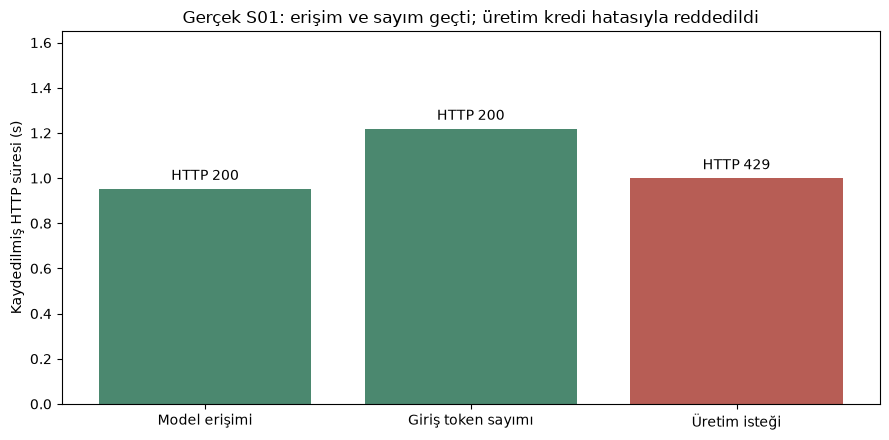

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S01_run_review_v1'
F=ROOT/'reports/figures/WP12/openai_S01_run_review_v1';F.mkdir(parents=True,exist_ok=True)
r=json.loads((Q/'independent_review.json').read_text(encoding='utf-8'))
stages=pd.read_csv(Q/'real_HTTP_stages.csv');display(stages)
fig,ax=plt.subplots(figsize=(9,4.5))
bars=ax.bar(['Model erişimi','Giriş token sayımı','Üretim isteği'],stages.elapsed_seconds,color=['#4b886f','#4b886f','#b75d55'])
ax.bar_label(bars,labels=[f"HTTP {x}" for x in stages.HTTP_status],padding=4)
ax.set(ylabel='Kaydedilmiş HTTP süresi (s)',ylim=(0,1.65),title='Gerçek S01: erişim ve sayım geçti; üretim kredi hatasıyla reddedildi')
plt.tight_layout();plt.savefig(F/'01_real_HTTP_stages.png',dpi=160);plt.show()


**Yorum:** Model GET ve tam giriş sayımı200, üretim429'dur. Üretim isteği gerçekten gönderilmiş, fakat kaynaklı açıklama alınamamıştır. Bu üç çağrıyı üç inference olarak saymıyoruz: bir üretim denemesi, sıfır tamamlanmış üretim vardır. Süreler model token üretim gecikmesi değildir.

## Kaynak, token ve bütçe

In [2]:

display(pd.DataFrame([{'alan':'Sayım endpoint giriş tokenı','değer':r['input_token_preflight_count']},
 {'alan':'Tamamlanmış üretim','değer':r['completed_generations']},
 {'alan':'Varsayımsal inference maliyet üstü USD','değer':r['preflight_cost_NOT_actual_charge']['worst_case_no_cache_USD']},
 {'alan':'%20 paylı planlama USD','değer':r['preflight_cost_NOT_actual_charge']['margin_upper_USD']},
 {'alan':'Ayrılmış rezerv; gerçek ücret değil USD','değer':r['recorded_reservations_NOT_actual_charge_USD']},
 {'alan':'Gerçek ücret / usage','değer':'UNKNOWN / kullanım yanıtı yok'}]))
display(pd.DataFrame([r['provider_error']]))


,alan,değer
0,Sayım endpoint giriş tokenı,1236
1,Tamamlanmış üretim,0
2,Varsayımsal inference maliyet üstü USD,0.006327
3,%20 paylı planlama USD,0.00759240
4,Ayrılmış rezerv; gerçek ücret değil USD,0.023
5,Gerçek ücret / usage,UNKNOWN / kullanım yanıtı yok


,provider_error_body,type,code
0,WITHHELD_SECURITY_POLICY,insufficient_quota,credit_balance_exhausted


**Yorum:**1236 token, üretimin faturalandırılmış giriş miktarı değildir; ayrı sayım endpoint'inin önkontrol sonucudur. $0,006327 varsayımsal üst token maliyeti ve$0,0075924 paylı hesap gerçek ücret değildir. Usage, output/cache/reasoning tokenları ve gerçek fatura UNKNOWN tutulur; sıfır ücret varsayılmaz. Tam error.message güvenlik nedeniyle saklanmadığından bilinmiyor; kayıtlı type/code yeterince açıktır.

## Teknik kontrol ve bilimsel sınıflandırma

In [3]:

display(pd.read_csv(Q/'review_checks.csv'))
display(pd.DataFrame([{'boyut':k,'durum':r[k]} for k in ['classification','schema_status','Turkish_quality','source_faithfulness','human_review']]))
display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))


,check,pass
0,run_file_hashes_all_match,True
1,run_manifest_matches_file_inventory,True
2,run_request_hash_matches_record,True
3,prompt_component_hashes_match,True
4,frozen_source_and_request_equal,True
5,prepared_public_artifacts_unchanged,True
6,policy_public_dependencies_unchanged,True
7,one_recorded_inference_attempt,True
8,three_HTTP_attempts,True
9,stages_200_200_429,True


,boyut,durum
0,classification,API_BILLING_BLOCKED_NO_MODEL_OUTPUT
1,schema_status,NOT_EVALUABLE_NO_OUTPUT
2,Turkish_quality,NOT_EVALUABLE_NO_OUTPUT
3,source_faithfulness,NOT_EVALUABLE_NO_OUTPUT
4,human_review,PENDING_NO_OUTPUT_TO_REVIEW


,tests,returncode,status,new_API_requests
0,9,0,PASS,0


**Sonuç:** İki özgün alıntı, S01 sorusu, kaynak kimlikleri, prompt ve şema onaylı istekle aynı; hash kontrolleri başarılı. Şema/Türkçe/kaynak sadakati yanıt olmadığı için değerlendirilemez.Yalnız429 genel koduna bakılarak otomatik retry yapılmadı; özel `credit_balance_exhausted` kodu faturalama engelidir. Modelin kötü açıklama ürettiği sonucu çıkarılamaz.

En küçük sonraki adım: kullanılan API anahtarının bağlı olduğu organizasyonda API Billing bakiyesini kontrol etmek. Kullanıcının gördüğü$5 ile bu isteğin organizasyon/bakiyesi arasındaki ilişki loglardan saptanamaz. Yeni ödeme, anahtar değişimi, slot resetleme veya tekrar bu notebook tarafından yapılmaz. Mevcut billing-stop ve ilk başarısız kayıt korunur. [OpenAI Docs hata açıklaması](https://developers.openai.com/api/docs/guides/error-codes).